# Laboratorio 3 — Reidentificación de personas sin etiquetas

## Pseudo-Labelling for Enhanced Masked Autoencoders

**Objetivo.** Aprender representaciones de personas sin usar `person_ids` durante el entrenamiento y recuperar, para cada consulta, imágenes de la misma persona tomadas por cámaras distintas.

### Experimentos incluidos

| Experimento | Reconstrucción | Teacher(s) | Propósito |
|---|---|---|---|
| `mae_baseline` | Píxeles de parches ocultos | Ninguno | Modelo base |
| `single_teacher` | Tokens + pseudoetiquetas | Un teacher EMA | Ablación del desacoplamiento |
| `dual_teacher` | Tokens + pseudoetiquetas | Dos teachers EMA | Propuesta principal |

La implementación conserva las ideas centrales del paper: encoder ViT disperso, enmascaramiento, reconstrucción en espacio de tokens, pseudoetiquetado global/local y teachers actualizados por EMA. Se reduce el tamaño del ViT y el número de épocas para adaptarlo a Market-1501 y a una sola GPU.

> **Regla contra fuga de información:** las identidades (`person_ids`) no se leen en entrenamiento. Solo se utilizan después, dentro de la evaluación de retrieval.

In [11]:
# 1. Importaciones, semilla y comprobación del entorno
from pathlib import Path
from dataclasses import dataclass, asdict
from copy import deepcopy
import csv, gc, json, math, os, random, time, warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Dispositivo:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

PyTorch: 2.11.0+cu128
CUDA disponible: True
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 5080 Laptop GPU
VRAM (GB): 15.92


In [12]:
# 2. Configuración experimental
@dataclass
class Config:
    data_dir: str = "data"
    image_h: int = 128
    image_w: int = 64
    patch_size: int = 16
    embed_dim: int = 192
    depth: int = 4
    num_heads: int = 6
    decoder_dim: int = 192
    decoder_depth: int = 2
    num_prototypes: int = 512
    mask_ratio: float = 0.75
    batch_size: int = 128
    eval_batch_size: int = 256
    epochs: int = 25
    warmup_epochs: int = 3
    lr: float = 2.5e-4
    weight_decay: float = 0.05
    num_workers: int = 0       # Lectura HDF5 en el proceso principal
    patience: int = 6
    lambda_rec: float = 1.0
    lambda_cls: float = 1.0
    lambda_patch: float = 1.0
    teacher_temp: float = 0.07
    student_temp: float = 0.1
    ema_label_start: float = 0.996
    ema_label_end: float = 1.0
    ema_recon_start: float = 0.96
    ema_recon_end: float = 0.99
    quick_test: bool = False   # True: prueba técnica de 1 época y 512 imágenes

CFG = Config()
ROOT = Path.cwd()
DATA_DIR = ROOT / CFG.data_dir
CHECKPOINT_DIR = ROOT / "checkpoints"
RESULTS_DIR = ROOT / "results"
CHECKPOINT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

TRAIN_H5 = DATA_DIR / "training.h5"
VAL_H5 = DATA_DIR / "validation.h5"
TEST_H5 = DATA_DIR / "testing.h5"
for p in (TRAIN_H5, VAL_H5, TEST_H5):
    print(("OK " if p.exists() else "FALTA ") + str(p))
assert all(p.exists() for p in (TRAIN_H5, VAL_H5, TEST_H5)), "Falta copiar algún .h5 dentro de data/"
print(json.dumps(asdict(CFG), indent=2))

OK c:\Users\nicol\OneDrive\Documents\Maestria\lab\data\training.h5
OK c:\Users\nicol\OneDrive\Documents\Maestria\lab\data\validation.h5
OK c:\Users\nicol\OneDrive\Documents\Maestria\lab\data\testing.h5
{
  "data_dir": "data",
  "image_h": 128,
  "image_w": 64,
  "patch_size": 16,
  "embed_dim": 192,
  "depth": 4,
  "num_heads": 6,
  "decoder_dim": 192,
  "decoder_depth": 2,
  "num_prototypes": 512,
  "mask_ratio": 0.75,
  "batch_size": 128,
  "eval_batch_size": 256,
  "epochs": 25,
  "warmup_epochs": 3,
  "lr": 0.00025,
  "weight_decay": 0.05,
  "num_workers": 0,
  "patience": 6,
  "lambda_rec": 1.0,
  "lambda_cls": 1.0,
  "lambda_patch": 1.0,
  "teacher_temp": 0.07,
  "student_temp": 0.1,
  "ema_label_start": 0.996,
  "ema_label_end": 1.0,
  "ema_recon_start": 0.96,
  "ema_recon_end": 0.99,
  "quick_test": false
}


## 1. Datos, dos vistas aumentadas y degradación low-resolution

- La vista **simple** mantiene la geometría y alimenta al student y al teacher de reconstrucción.
- La vista **compleja** aplica cambios más fuertes y alimenta al teacher de pseudoetiquetado.
- La función `make_low_resolution` simula una consulta degradada reduciendo y reescalando la imagen.
- `H5TrainingDataset` devuelve únicamente imágenes: nunca abre identidades.

In [24]:
# 3. Utilidades robustas para imágenes CHW/HWC y HDF5
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

def to_pil(arr):
    arr = np.asarray(arr)
    if arr.ndim == 3 and arr.shape[0] in (1, 3, 4):
        arr = np.transpose(arr, (1, 2, 0))
    if arr.dtype != np.uint8:
        if arr.max() <= 1.0: arr = arr * 255.0
        arr = np.clip(arr, 0, 255).astype(np.uint8)
    if arr.shape[-1] == 1: arr = arr[..., 0]
    return Image.fromarray(arr).convert("RGB")

def denormalize(x):
    mean = torch.tensor(IMAGENET_MEAN, device=x.device)[:, None, None]
    std = torch.tensor(IMAGENET_STD, device=x.device)[:, None, None]
    return (x * std + mean).clamp(0, 1)

normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
simple_aug = transforms.Compose([
    transforms.Resize((CFG.image_h, CFG.image_w), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(), normalize,
])
complex_aug = transforms.Compose([
    transforms.RandomResizedCrop((CFG.image_h, CFG.image_w), scale=(0.65, 1.0), ratio=(0.42, 0.58), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([transforms.ColorJitter(0.35, 0.35, 0.25, 0.08)], p=0.8),
    transforms.RandomGrayscale(p=0.15), transforms.GaussianBlur(5, sigma=(0.1, 1.5)),
    transforms.ToTensor(), normalize,
])
eval_transform = transforms.Compose([
    transforms.Resize((CFG.image_h, CFG.image_w), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(), normalize,
])

def make_low_resolution(img, scale=None):
    """Reduce y reescala una imagen PIL para simular pérdida de detalle."""
    if scale is None: scale = random.choice([2, 3, 4])
    small = img.resize((max(4, CFG.image_w // scale), max(8, CFG.image_h // scale)), Image.Resampling.BILINEAR)
    return small.resize((CFG.image_w, CFG.image_h), Image.Resampling.BICUBIC)

class H5TrainingDataset(Dataset):
    def __init__(self, path, limit=None):
        self.path = str(path); self._h5 = None
        with h5py.File(self.path, "r") as f:
            self.n = len(f["images"])
            assert "person_ids" not in f, "Fuga: training.h5 no debe usar person_ids"
        if limit: self.n = min(self.n, limit)
    def __len__(self): return self.n
    def _file(self):
        if self._h5 is None: self._h5 = h5py.File(self.path, "r")
        return self._h5
    def __getitem__(self, idx):
        pil = to_pil(self._file()["images"][idx])
        return simple_aug(pil), complex_aug(pil), eval_transform(make_low_resolution(pil))
    def __del__(self):
        try:
            if self._h5 is not None: self._h5.close()
        except Exception: pass

class H5EvalDataset(Dataset):
    def __init__(self, path, group, low_resolution=False, limit=None):
        self.path = str(path); self.group = group; self._h5 = None
        self.image_key = "images_low_resolution" if low_resolution else "images"
        with h5py.File(self.path, "r") as f: self.n = len(f[f"{group}/{self.image_key}"])
        if limit: self.n = min(self.n, limit)
    def __len__(self): return self.n
    def _file(self):
        if self._h5 is None: self._h5 = h5py.File(self.path, "r")
        return self._h5
    def __getitem__(self, idx):
        f = self._file(); g = f[self.group]
        return (eval_transform(to_pil(g[self.image_key][idx])),
                int(g["person_ids"][idx]), int(g["camera_ids"][idx]), g["image_ids"][idx])
    def __del__(self):
        try:
            if self._h5 is not None: self._h5.close()
        except Exception: pass

Entrenamiento: 11043 imágenes | lote: (128, 3, 128, 64)


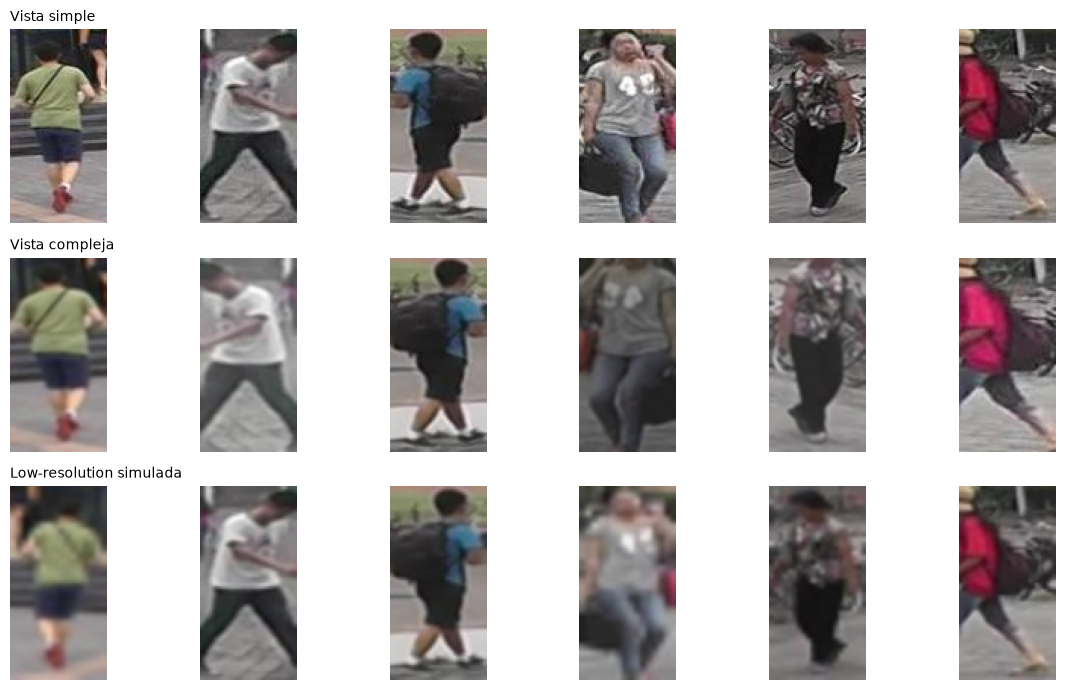

In [14]:
# 4. DataLoader de entrenamiento y comprobación visual
limit = 512 if CFG.quick_test else None
train_ds = H5TrainingDataset(TRAIN_H5, limit=limit)
train_loader = DataLoader(train_ds, batch_size=CFG.batch_size, shuffle=True,
                          num_workers=CFG.num_workers, pin_memory=True, drop_last=True)
simple, complex_, low = next(iter(train_loader))
print("Entrenamiento:", len(train_ds), "imágenes | lote:", tuple(simple.shape))

fig, ax = plt.subplots(3, 6, figsize=(12, 7))
for j, (batch, title) in enumerate([(simple,"Vista simple"),(complex_,"Vista compleja"),(low,"Low-resolution simulada")]):
    for i in range(6):
        ax[j,i].imshow(denormalize(batch[i]).permute(1,2,0)); ax[j,i].axis("off")
        if i == 0: ax[j,i].set_title(title, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 2. Arquitectura

El student divide cada imagen en parches, elimina el 75% y procesa únicamente los visibles. El decoder reinserta tokens máscara.

- **Baseline:** predice los píxeles normalizados de los parches ocultos.
- **Single teacher:** un EMA teacher proporciona tokens de reconstrucción y pseudoetiquetas.
- **Dual teacher:** un teacher estable genera tokens; otro, actualizado por iteración, genera pseudoetiquetas globales y locales.

La pérdida final de la propuesta es:

\[
L = \lambda_m L_m + \lambda_c L_c + \lambda_p L_p
\]

El emparejamiento local usa máxima similitud coseno, necesario porque las vistas simple y compleja no están espacialmente alineadas.

In [15]:
# 5. Bloques ViT, patchify y máscara aleatoria
class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0, drop=0.0):
        super().__init__()
        self.n1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=drop, batch_first=True)
        self.n2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, dim))
    def forward(self, x):
        y = self.n1(x); x = x + self.attn(y, y, y, need_weights=False)[0]
        return x + self.mlp(self.n2(x))

def patchify(imgs, p):
    b, c, h, w = imgs.shape
    x = imgs.reshape(b, c, h//p, p, w//p, p).permute(0,2,4,3,5,1)
    return x.reshape(b, (h//p)*(w//p), p*p*c)

def random_mask_indices(batch, n_patches, mask_ratio, device):
    n_keep = max(1, int(n_patches * (1-mask_ratio)))
    noise = torch.rand(batch, n_patches, device=device)
    order = noise.argsort(dim=1)
    keep = order[:, :n_keep]
    mask = torch.ones(batch, n_patches, dtype=torch.bool, device=device)
    mask.scatter_(1, keep, False)
    return keep, mask

def batched_gather(x, idx):
    return torch.gather(x, 1, idx.unsqueeze(-1).expand(-1, -1, x.size(-1)))

class ViTEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        p=cfg.patch_size; self.np=(cfg.image_h//p)*(cfg.image_w//p); self.dim=cfg.embed_dim
        self.patch = nn.Conv2d(3, cfg.embed_dim, p, p)
        self.cls = nn.Parameter(torch.zeros(1,1,cfg.embed_dim))
        self.pos = nn.Parameter(torch.zeros(1,self.np+1,cfg.embed_dim))
        self.blocks = nn.ModuleList([TransformerBlock(cfg.embed_dim,cfg.num_heads) for _ in range(cfg.depth)])
        self.norm = nn.LayerNorm(cfg.embed_dim)
        nn.init.trunc_normal_(self.pos,std=.02); nn.init.trunc_normal_(self.cls,std=.02)
    def tokens(self,x): return self.patch(x).flatten(2).transpose(1,2)
    def forward(self,x,keep_idx=None):
        t=self.tokens(x); b=t.size(0)
        if keep_idx is None:
            t=t+self.pos[:,1:]
        else:
            t=batched_gather(t,keep_idx)+batched_gather(self.pos[:,1:].expand(b,-1,-1),keep_idx)
        z=torch.cat([self.cls.expand(b,-1,-1)+self.pos[:,:1],t],1)
        for block in self.blocks: z=block(z)
        return self.norm(z)

class ProjectionHead(nn.Module):
    def __init__(self,dim,k):
        super().__init__(); self.net=nn.Sequential(nn.Linear(dim,dim),nn.GELU(),nn.Linear(dim,k,bias=False))
    def forward(self,x): return self.net(x)

class PseudoMAE(nn.Module):
    def __init__(self,cfg,mode):
        super().__init__(); self.cfg=cfg; self.mode=mode; self.encoder=ViTEncoder(cfg)
        self.enc_to_dec=nn.Linear(cfg.embed_dim,cfg.decoder_dim)
        self.mask_token=nn.Parameter(torch.zeros(1,1,cfg.decoder_dim))
        self.dec_pos=nn.Parameter(torch.zeros(1,self.encoder.np+1,cfg.decoder_dim))
        self.decoder=nn.ModuleList([TransformerBlock(cfg.decoder_dim,4) for _ in range(cfg.decoder_depth)])
        self.dec_norm=nn.LayerNorm(cfg.decoder_dim)
        out_dim=cfg.patch_size*cfg.patch_size*3 if mode=="mae_baseline" else cfg.embed_dim
        self.recon_head=nn.Linear(cfg.decoder_dim,out_dim)
        self.student_proj=ProjectionHead(cfg.decoder_dim,cfg.num_prototypes)
        nn.init.trunc_normal_(self.mask_token,std=.02); nn.init.trunc_normal_(self.dec_pos,std=.02)
    def forward(self,x,keep,mask):
        b=x.size(0); enc=self.encoder(x,keep); cls=self.enc_to_dec(enc[:,:1]); vis=self.enc_to_dec(enc[:,1:])
        # Con autocast, `vis` puede ser float16 y el parámetro mask_token float32.
        # scatter_ exige el mismo dtype para destino y fuente.
        patches=self.mask_token.to(dtype=vis.dtype).expand(b,self.encoder.np,-1).clone()
        patches.scatter_(1,keep.unsqueeze(-1).expand(-1,-1,patches.size(-1)),vis)
        z=torch.cat([cls,patches],1)+self.dec_pos
        for block in self.decoder: z=block(z)
        z=self.dec_norm(z)
        return z, self.recon_head(z[:,1:]), self.student_proj(z)

In [16]:
# 6. Teachers, Sinkhorn y funciones de pérdida
@torch.no_grad()
def ema_update(teacher, student, momentum):
    for pt, ps in zip(teacher.parameters(), student.parameters()):
        pt.data.mul_(momentum).add_(ps.data, alpha=1-momentum)

@torch.no_grad()
def sinkhorn_probs(logits, eps=0.05, iterations=3):
    # Asignaciones balanceadas entre prototipos para reducir el colapso.
    shape=logits.shape; flat=logits.reshape(-1,shape[-1]).float()
    flat=flat-flat.max(dim=1,keepdim=True).values
    q=torch.exp(flat/eps).t()
    q=q/(q.sum()+1e-6); k,b=q.shape
    for _ in range(iterations):
        q=q/(q.sum(1,keepdim=True)+1e-6)/k
        q=q/(q.sum(0,keepdim=True)+1e-6)/b
    return (q*b).t().reshape(shape).detach()

def soft_cross_entropy(student_logits, teacher_prob, temp):
    return -(teacher_prob * F.log_softmax(student_logits/temp,dim=-1)).sum(-1).mean()

def masked_cosine_loss(pred,target,mask):
    pred=F.normalize(pred,dim=-1); target=F.normalize(target,dim=-1)
    return (1-(pred*target).sum(-1))[mask].mean()

@torch.no_grad()
def teacher_targets(teacher, head, x):
    z=teacher(x); return z[:,0], z[:,1:], head(z)

def nearest_patch_targets(student_feat, teacher_feat, teacher_probs):
    # student_feat [B,N,Ds], teacher_feat [B,N,Dt]; usa dimensión común mínima
    d=min(student_feat.size(-1),teacher_feat.size(-1))
    s=F.normalize(student_feat[...,:d],dim=-1); t=F.normalize(teacher_feat[...,:d],dim=-1)
    match=torch.bmm(s,t.transpose(1,2)).argmax(-1)
    return batched_gather(teacher_probs,match)

def cosine_schedule(start,end,step,total):
    return end-(end-start)*(math.cos(math.pi*step/max(total,1))+1)/2

## 3. Entrenamiento reproducible y reanudable

Cada corrida guarda:

- `*_last.pt`: estado completo para reanudar.
- `*_best.pt`: encoder con menor pérdida autosupervisada durante el preentrenamiento.
- `history_*.csv`: pérdidas por época.

La ejecución detecta los checkpoints `*_last.pt` existentes y reanuda cada experimento desde la siguiente época registrada.

In [17]:
# 7. Construcción de cada experimento
def build_experiment(mode,cfg):
    model=PseudoMAE(cfg,mode).to(DEVICE)
    teachers={}; heads={}
    if mode=="single_teacher":
        teachers["shared"]=deepcopy(model.encoder).eval().requires_grad_(False)
        heads["shared"]=ProjectionHead(cfg.embed_dim,cfg.num_prototypes).to(DEVICE).eval().requires_grad_(False)
    elif mode=="dual_teacher":
        teachers["recon"]=deepcopy(model.encoder).eval().requires_grad_(False)
        teachers["label"]=deepcopy(model.encoder).eval().requires_grad_(False)
        heads["label"]=ProjectionHead(cfg.embed_dim,cfg.num_prototypes).to(DEVICE).eval().requires_grad_(False)
    # teacher projection starts from a dimension-compatible independent head and follows student head partially via EMA
    return model,teachers,heads

def update_head_ema(teacher_head,student_head,m):
    # Heads have different input dims (teacher embed vs decoder dim); update only tensors of identical shape.
    with torch.no_grad():
        ts=dict(teacher_head.named_parameters()); ss=dict(student_head.named_parameters())
        for n,p in ts.items():
            if n in ss and p.shape==ss[n].shape: p.data.mul_(m).add_(ss[n].data,alpha=1-m)

def save_checkpoint(path,epoch,model,teachers,heads,opt,sched,scaler,best,history):
    torch.save({"epoch":epoch,"model":model.state_dict(),"teachers":{k:v.state_dict() for k,v in teachers.items()},
                "heads":{k:v.state_dict() for k,v in heads.items()},"optimizer":opt.state_dict(),
                "scheduler":sched.state_dict(),"scaler":scaler.state_dict(),"best":best,"history":history,
                "config":asdict(CFG)},path)

def load_checkpoint(path,model,teachers,heads,opt=None,sched=None,scaler=None):
    ck=torch.load(path,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"])
    for k,v in teachers.items(): v.load_state_dict(ck["teachers"][k])
    for k,v in heads.items(): v.load_state_dict(ck["heads"][k])
    if opt: opt.load_state_dict(ck["optimizer"])
    if sched: sched.load_state_dict(ck["scheduler"])
    if scaler and "scaler" in ck: scaler.load_state_dict(ck["scaler"])
    return ck

In [18]:
# 8. Una época de entrenamiento
def train_epoch(mode,model,teachers,heads,loader,opt,scaler,epoch,total_steps,cfg):
    model.train(); sums={"loss":0.,"rec":0.,"cls":0.,"patch":0.}; n=0
    amp_enabled=DEVICE.type=="cuda"
    for it,(x_simple,x_complex,x_low) in enumerate(loader):
        x_simple=x_simple.to(DEVICE,non_blocking=True); x_complex=x_complex.to(DEVICE,non_blocking=True)
        b=x_simple.size(0); keep,mask=random_mask_indices(b,model.encoder.np,cfg.mask_ratio,DEVICE)
        global_step=epoch*len(loader)+it
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=amp_enabled):
            dec,recon,student_logits=model(x_simple,keep,mask)
            loss_cls=torch.zeros((),device=DEVICE); loss_patch=torch.zeros((),device=DEVICE)
            if mode=="mae_baseline":
                target=patchify(x_simple,cfg.patch_size)
                target=(target-target.mean(-1,keepdim=True))/(target.var(-1,keepdim=True)+1e-6).sqrt()
                loss_rec=F.mse_loss(recon[mask],target[mask])
            else:
                if mode=="single_teacher":
                    t_rec=t_label=teachers["shared"]; h_label=heads["shared"]
                else:
                    t_rec=teachers["recon"]; t_label=teachers["label"]; h_label=heads["label"]
                with torch.no_grad():
                    rec_tokens=t_rec(x_simple)[:,1:]
                    _,teacher_patches,teacher_logits=teacher_targets(t_label,h_label,x_complex)
                    teacher_prob=sinkhorn_probs(teacher_logits,cfg.teacher_temp)
                loss_rec=masked_cosine_loss(recon,rec_tokens,mask)
                loss_cls=soft_cross_entropy(student_logits[:,0],teacher_prob[:,0],cfg.student_temp)
                matched=nearest_patch_targets(dec[:,1:],teacher_patches,teacher_prob[:,1:])
                loss_patch=soft_cross_entropy(student_logits[:,1:][mask],matched[mask],cfg.student_temp)
            loss=cfg.lambda_rec*loss_rec+cfg.lambda_cls*loss_cls+cfg.lambda_patch*loss_patch
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        scaler.step(opt); scaler.update()
        if mode=="single_teacher":
            m=cosine_schedule(cfg.ema_label_start,cfg.ema_label_end,global_step,total_steps)
            ema_update(teachers["shared"],model.encoder,m); update_head_ema(heads["shared"],model.student_proj,m)
        elif mode=="dual_teacher":
            m=cosine_schedule(cfg.ema_label_start,cfg.ema_label_end,global_step,total_steps)
            ema_update(teachers["label"],model.encoder,m); update_head_ema(heads["label"],model.student_proj,m)
        sums["loss"]+=loss.item(); sums["rec"]+=loss_rec.item(); sums["cls"]+=loss_cls.item(); sums["patch"]+=loss_patch.item(); n+=1
        if (it+1)%25==0: print(f"  batch {it+1:>4}/{len(loader)} loss={sums['loss']/n:.4f}",end="\r")
    return {k:v/max(n,1) for k,v in sums.items()}

In [19]:
# 9. Bucle completo con checkpoints y parada temprana
def run_experiment(mode,cfg=CFG):
    print("\n"+"="*72+f"\nEXPERIMENTO: {mode}\n"+"="*72)
    model,teachers,heads=build_experiment(mode,cfg)
    params=list(model.parameters())
    opt=torch.optim.AdamW(params,lr=cfg.lr,weight_decay=cfg.weight_decay,betas=(0.9,0.95))
    epochs=1 if cfg.quick_test else cfg.epochs
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=max(epochs,1),eta_min=cfg.lr*0.05)
    scaler=torch.amp.GradScaler("cuda",enabled=DEVICE.type=="cuda")
    last=CHECKPOINT_DIR/f"{mode}_last.pt"; best_path=CHECKPOINT_DIR/f"{mode}_best.pt"
    start=0; best=float("inf"); bad=0; history=[]
    if last.exists() and not cfg.quick_test:
        ck=load_checkpoint(last,model,teachers,heads,opt,sched,scaler)
        start=ck["epoch"]+1; best=ck.get("best",best); history=ck.get("history",[])
        print(f"Reanudando desde época {start+1}")
    total_steps=epochs*len(train_loader)
    for epoch in range(start,epochs):
        t=time.time(); stats=train_epoch(mode,model,teachers,heads,train_loader,opt,scaler,epoch,total_steps,cfg)
        if mode=="dual_teacher":
            m=cosine_schedule(cfg.ema_recon_start,cfg.ema_recon_end,epoch,epochs)
            ema_update(teachers["recon"],model.encoder,m)  # actualización por época según el paper
        sched.step(); stats.update(epoch=epoch+1,lr=opt.param_groups[0]["lr"],minutes=(time.time()-t)/60)
        history.append(stats); print(f"Época {epoch+1:>3}/{epochs} | loss {stats['loss']:.4f} | rec {stats['rec']:.4f} | cls {stats['cls']:.4f} | patch {stats['patch']:.4f} | {stats['minutes']:.1f} min")
        save_checkpoint(last,epoch,model,teachers,heads,opt,sched,scaler,best,history)
        if stats["loss"]<best:
            best=stats["loss"]; bad=0
            save_checkpoint(best_path,epoch,model,teachers,heads,opt,sched,scaler,best,history)
        else: bad+=1
        if bad>=cfg.patience and epoch>=cfg.warmup_epochs:
            print("Parada temprana por falta de mejora."); break
    with open(RESULTS_DIR/f"history_{mode}.csv","w",newline="") as f:
        w=csv.DictWriter(f,fieldnames=history[0].keys()); w.writeheader(); w.writerows(history)
    del model,teachers,heads,opt; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return history

## 4. Entrenamiento de los tres experimentos

Se entrenan secuencialmente el modelo base, la variante con un teacher y la propuesta con dos teachers. La configuración establece 25 épocas por experimento, con parada temprana según la pérdida de entrenamiento y almacenamiento de checkpoints e historiales.

Los resultados registrados corresponden a la configuración completa (`quick_test=False`). El modo de comprobación (`quick_test=True`) limita el entrenamiento a una época y 512 imágenes.


In [20]:
# 10. Entrenamiento de los tres experimentos
RUN_EXPERIMENTS = ["mae_baseline", "single_teacher", "dual_teacher"]
all_histories = {}
for experiment in RUN_EXPERIMENTS:
    all_histories[experiment] = run_experiment(experiment)
print("\nEntrenamientos terminados. Checkpoints guardados en:", CHECKPOINT_DIR)


EXPERIMENTO: mae_baseline
Época   1/25 | loss 0.9663 | rec 0.9663 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   2/25 | loss 0.9175 | rec 0.9175 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   3/25 | loss 0.8946 | rec 0.8946 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   4/25 | loss 0.8837 | rec 0.8837 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   5/25 | loss 0.8782 | rec 0.8782 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   6/25 | loss 0.8723 | rec 0.8723 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   7/25 | loss 0.8671 | rec 0.8671 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   8/25 | loss 0.8620 | rec 0.8620 | cls 0.0000 | patch 0.0000 | 0.5 min
Época   9/25 | loss 0.8589 | rec 0.8589 | cls 0.0000 | patch 0.0000 | 0.5 min
Época  10/25 | loss 0.8544 | rec 0.8544 | cls 0.0000 | patch 0.0000 | 0.5 min
Época  11/25 | loss 0.8513 | rec 0.8513 | cls 0.0000 | patch 0.0000 | 0.5 min
Época  12/25 | loss 0.8470 | rec 0.8470 | cls 0.0000 | patch 0.0000 | 0.5 min
Época  13/25 | loss 0.8428 | rec 0.84

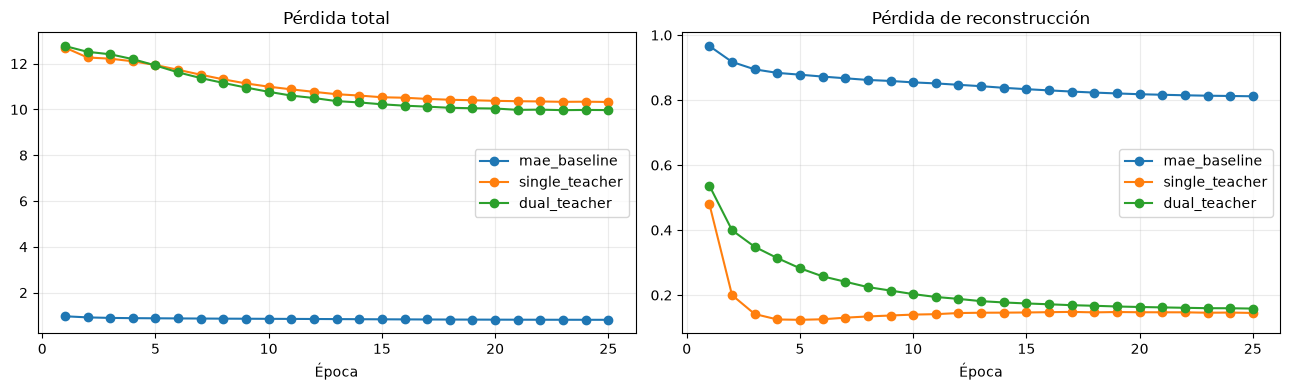

In [21]:
# 11. Curvas de pérdida para comparar convergencia
fig,ax=plt.subplots(1,2,figsize=(13,4))
for mode in RUN_EXPERIMENTS:
    p=RESULTS_DIR/f"history_{mode}.csv"
    if not p.exists(): continue
    data=np.genfromtxt(p,delimiter=",",names=True)
    data=np.atleast_1d(data)
    ax[0].plot(data["epoch"],data["loss"],marker="o",label=mode)
    ax[1].plot(data["epoch"],data["rec"],marker="o",label=mode)
ax[0].set_title("Pérdida total"); ax[1].set_title("Pérdida de reconstrucción")
for a in ax: a.set_xlabel("Época"); a.grid(alpha=.25); a.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR/"training_curves.png",dpi=160); plt.show()

## 5. Evaluación ReID

Se extrae el token `[CLS]` del encoder, se normaliza con L2 y se ordena la galería mediante similitud coseno. Siguiendo Market-1501, se eliminan de cada ranking las imágenes de la misma identidad capturadas por la misma cámara.

Métricas: mAP, Rank-1, Rank-5, Rank-10 y caída de mAP con consultas low-resolution.

In [25]:
# 12. Extracción de embeddings y métricas Market-1501
@torch.inference_mode()
def extract_embeddings(encoder,loader):
    encoder.eval(); feats=[]; pids=[]; cams=[]; ids=[]
    for x,p,c,i in loader:
        x=x.to(DEVICE,non_blocking=True)
        z=F.normalize(encoder(x)[:,0].float(),dim=-1).cpu()
        feats.append(z); pids.append(torch.as_tensor(p)); cams.append(torch.as_tensor(c)); ids.extend(i)
    return torch.cat(feats),torch.cat(pids).numpy(),torch.cat(cams).numpy(),np.asarray(ids)

def reid_metrics(qf,qpid,qcam,gf,gpid,gcam,max_rank=10,return_rankings=False):
    qf=F.normalize(qf.float(),dim=1); gf=F.normalize(gf.float(),dim=1)
    aps=[]; cmcs=[]; rankings=[]
    for start in range(0,len(qf),128):
        sim=(qf[start:start+128]@gf.t()).numpy()
        for j,row in enumerate(sim):
            qi=start+j; order=np.argsort(-row)
            remove=(gpid[order]==qpid[qi])&(gcam[order]==qcam[qi])
            order=order[~remove]; matches=(gpid[order]==qpid[qi]).astype(np.int32)
            if matches.sum()==0: continue
            hit=np.where(matches==1)[0]; cmc=np.zeros(max_rank,dtype=np.float32)
            first=hit[0]
            if first<max_rank: cmc[first:]=1
            precision=np.cumsum(matches)/(np.arange(len(matches))+1)
            aps.append(float((precision*matches).sum()/matches.sum())); cmcs.append(cmc)
            if return_rankings: rankings.append((qi,order,row[order],bool(first==0),aps[-1]))
    if not aps:
        result={"mAP":float("nan"),"Rank-1":float("nan"),"Rank-5":float("nan"),"Rank-10":float("nan"),"valid_queries":0}
        return (result,rankings) if return_rankings else result
    cmc=np.mean(cmcs,axis=0)
    result={"mAP":100*np.mean(aps),"Rank-1":100*cmc[0],"Rank-5":100*cmc[min(4,max_rank-1)],"Rank-10":100*cmc[min(9,max_rank-1)],"valid_queries":len(aps)}
    return (result,rankings) if return_rankings else result

def load_best_encoder(mode,cfg=CFG):
    model,teachers,heads=build_experiment(mode,cfg)
    path=CHECKPOINT_DIR/f"{mode}_best.pt"
    assert path.exists(),f"No existe {path}; primero entrene el experimento."
    load_checkpoint(path,model,teachers,heads)
    return model.encoder.eval()

In [27]:
# 13. Validación: originales y low-resolution para seleccionar configuración
import gc

def make_eval_loaders(path,limit=None):
    common=dict(batch_size=CFG.eval_batch_size,shuffle=False,num_workers=CFG.num_workers,pin_memory=True)
    q=DataLoader(H5EvalDataset(path,"query",False,limit),**common)
    qlow=DataLoader(H5EvalDataset(path,"query",True,limit),**common)
    g=DataLoader(H5EvalDataset(path,"gallery",False,limit),**common)
    return q,qlow,g

val_limit=256 if CFG.quick_test else None
vq,vql,vg=make_eval_loaders(VAL_H5,val_limit)
validation_rows=[]
for mode in RUN_EXPERIMENTS:
    enc=load_best_encoder(mode)
    qf,qp,qc,qi=extract_embeddings(enc,vq); lqf,lqp,lqc,lqi=extract_embeddings(enc,vql)
    gf,gp,gcam,gi=extract_embeddings(enc,vg)
    original=reid_metrics(qf,qp,qc,gf,gp,gcam); lowres=reid_metrics(lqf,lqp,lqc,gf,gp,gcam)
    row={"modelo":mode,**{f"orig_{k}":v for k,v in original.items() if k!="valid_queries"},
         **{f"low_{k}":v for k,v in lowres.items() if k!="valid_queries"},"mAP_drop":original["mAP"]-lowres["mAP"]}
    validation_rows.append(row); print(row)
    del enc,qf,lqf,gf,gp,gcam,gi; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None

with open(RESULTS_DIR/"validation_metrics.csv","w",newline="") as f:
    w=csv.DictWriter(f,fieldnames=validation_rows[0].keys()); w.writeheader(); w.writerows(validation_rows)
BEST_MODE=max(validation_rows,key=lambda r:r["orig_mAP"])["modelo"]
print("\nConfiguración seleccionada exclusivamente con VALIDACIÓN:",BEST_MODE)

{'modelo': 'mae_baseline', 'orig_mAP': np.float64(9.649283174624088), 'orig_Rank-1': np.float32(14.0), 'orig_Rank-5': np.float32(35.0), 'orig_Rank-10': np.float32(44.0), 'low_mAP': np.float64(9.737462356518645), 'low_Rank-1': np.float32(14.0), 'low_Rank-5': np.float32(35.0), 'low_Rank-10': np.float32(45.0), 'mAP_drop': np.float64(-0.08817918189455654)}
{'modelo': 'single_teacher', 'orig_mAP': np.float64(11.590763195959756), 'orig_Rank-1': np.float32(20.0), 'orig_Rank-5': np.float32(41.0), 'orig_Rank-10': np.float32(51.0), 'low_mAP': np.float64(11.475597987758128), 'low_Rank-1': np.float32(20.0), 'low_Rank-5': np.float32(40.0), 'low_Rank-10': np.float32(49.0), 'mAP_drop': np.float64(0.11516520820162768)}
{'modelo': 'dual_teacher', 'orig_mAP': np.float64(13.305452384788751), 'orig_Rank-1': np.float32(21.0), 'orig_Rank-5': np.float32(42.0), 'orig_Rank-10': np.float32(51.0), 'low_mAP': np.float64(13.406288659508082), 'low_Rank-1': np.float32(24.0), 'low_Rank-5': np.float32(40.0), 'low_Rank

,modelo,orig_mAP,orig_Rank-1,orig_Rank-5,orig_Rank-10,low_mAP,low_Rank-1,low_Rank-5,low_Rank-10,mAP_drop
0,mae_baseline,9.65,14.0,35.0,44.0,9.74,14.0,35.0,45.0,-0.09
1,single_teacher,11.59,20.0,41.0,51.0,11.48,20.0,40.0,49.0,0.12
2,dual_teacher,13.31,21.0,42.0,51.0,13.41,24.0,40.0,50.0,-0.10


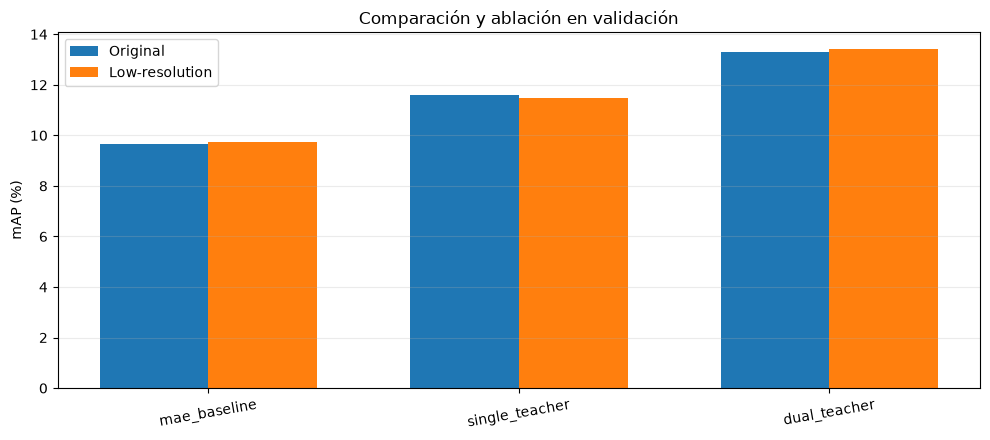

In [28]:
# 14. Tabla comparativa de baseline, ablación y propuesta
try:
    import pandas as pd
    display(pd.DataFrame(validation_rows).round(2))
except ImportError:
    for r in validation_rows: print(r)

labels=[r["modelo"] for r in validation_rows]; x=np.arange(len(labels)); width=.35
fig,ax=plt.subplots(figsize=(10,4.5))
ax.bar(x-width/2,[r["orig_mAP"] for r in validation_rows],width,label="Original")
ax.bar(x+width/2,[r["low_mAP"] for r in validation_rows],width,label="Low-resolution")
ax.set_xticks(x,labels,rotation=10); ax.set_ylabel("mAP (%)"); ax.set_title("Comparación y ablación en validación")
ax.legend(); ax.grid(axis="y",alpha=.25); plt.tight_layout(); plt.savefig(RESULTS_DIR/"validation_comparison.png",dpi=160); plt.show()

## 6. Evaluación final en test

**Importante:** el conjunto de prueba se evalúa una sola vez, después de elegir el modelo con validación. No se reajustan pesos, hiperparámetros ni umbrales con test.

In [30]:
# 15. Test final del modelo seleccionado
test_limit=512 if CFG.quick_test else None
tq,tql,tg=make_eval_loaders(TEST_H5,test_limit)
best_encoder=load_best_encoder(BEST_MODE)
tqf,tqp,tqc,tqi=extract_embeddings(best_encoder,tq)
tlqf,tlqp,tlqc,tlqi=extract_embeddings(best_encoder,tql)
tgf,tgp,tgc,tgi=extract_embeddings(best_encoder,tg)
test_original,test_rankings=reid_metrics(tqf,tqp,tqc,tgf,tgp,tgc,return_rankings=True)
test_low=reid_metrics(tlqf,tlqp,tlqc,tgf,tgp,tgc)
test_result={"modelo":BEST_MODE,**{f"original_{k}":v for k,v in test_original.items()},
             **{f"lowres_{k}":v for k,v in test_low.items()},"mAP_drop":test_original["mAP"]-test_low["mAP"]}
test_result={key:value.item() if isinstance(value,np.generic) else value for key,value in test_result.items()}
print(json.dumps(test_result,indent=2))
with open(RESULTS_DIR/"test_metrics.json","w") as f: json.dump(test_result,f,indent=2)

{
  "modelo": "dual_teacher",
  "original_mAP": 2.1985564918572136,
  "original_Rank-1": 4.513063907623291,
  "original_Rank-5": 11.846793174743652,
  "original_Rank-10": 17.33966827392578,
  "original_valid_queries": 3368,
  "lowres_mAP": 2.1508631499231066,
  "lowres_Rank-1": 4.275534152984619,
  "lowres_Rank-5": 11.31235122680664,
  "lowres_Rank-10": 17.280284881591797,
  "lowres_valid_queries": 3368,
  "mAP_drop": 0.047693341934107014
}


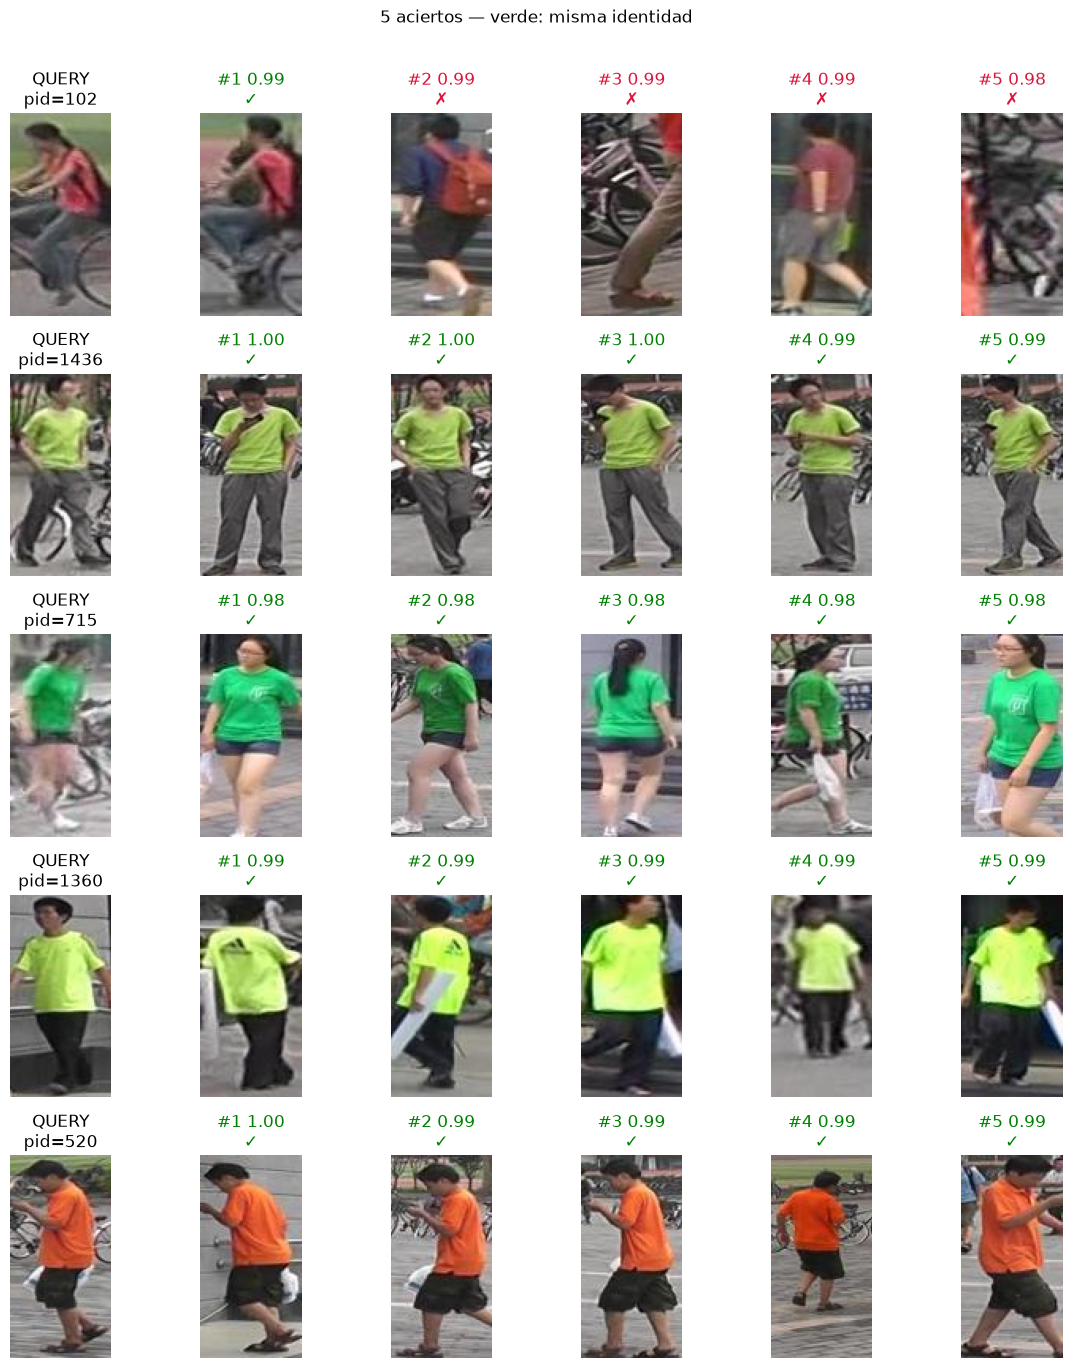

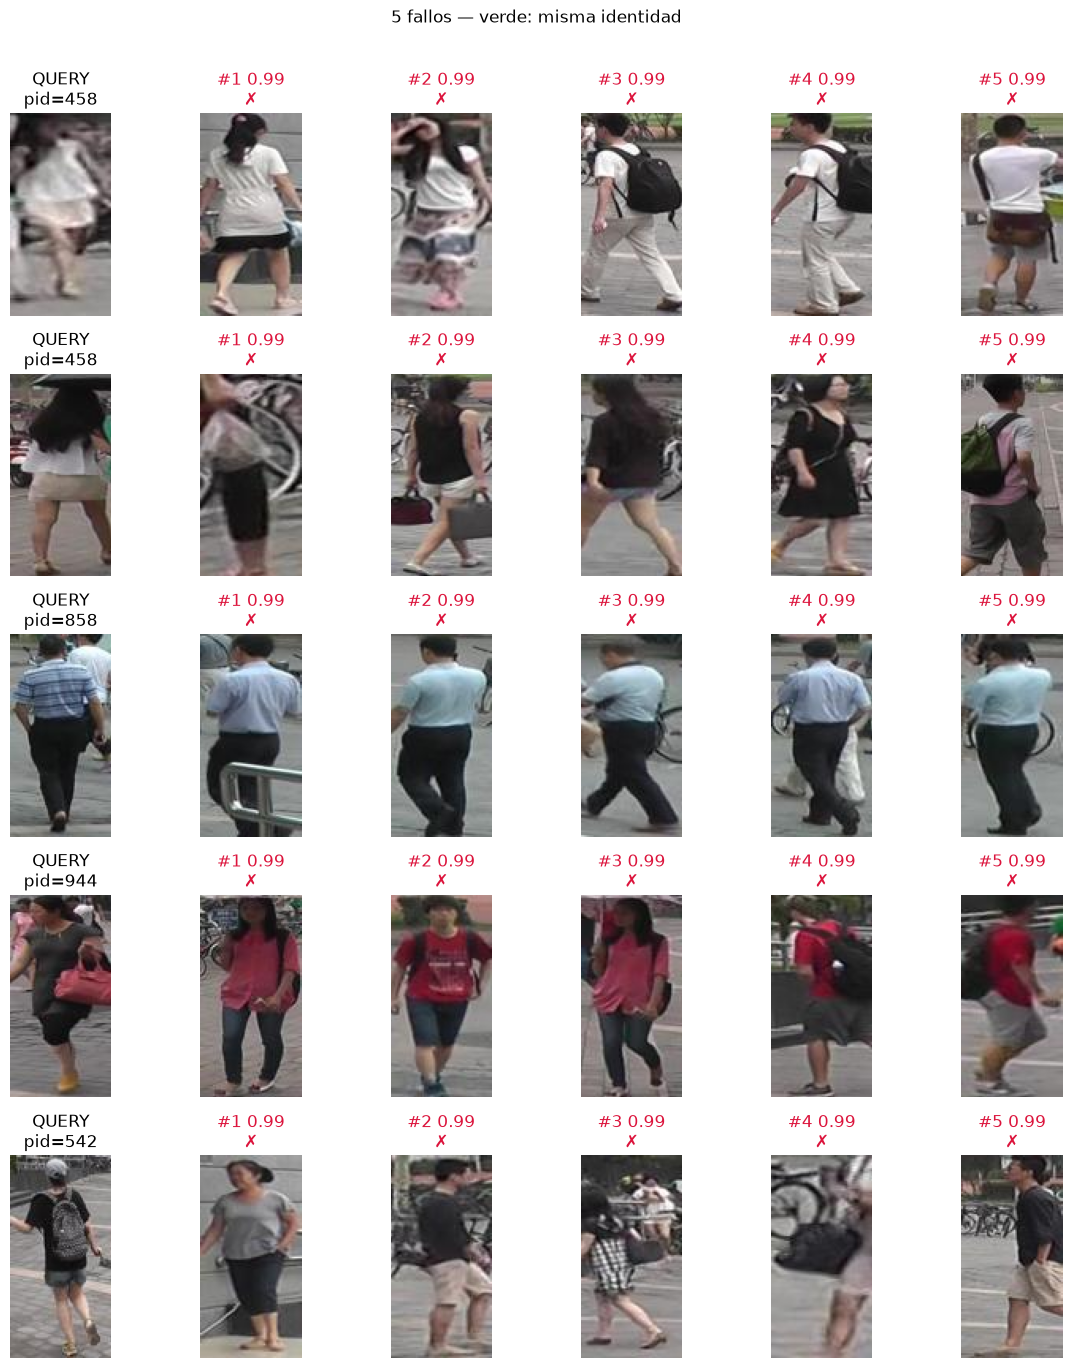

In [31]:
# 16. Recuperar imágenes originales para análisis cualitativo
def read_h5_image(path,group,index,key="images"):
    with h5py.File(path,"r") as f: return np.asarray(to_pil(f[f"{group}/{key}"][index]))

def plot_retrieval_cases(rankings,path,success=True,n_cases=5,topk=5,filename="cases.png"):
    selected=[r for r in rankings if r[3]==success]
    selected=sorted(selected,key=lambda z:z[4],reverse=success)[:n_cases]
    if not selected:
        print("No se encontraron casos", "exitosos" if success else "fallidos"); return
    fig,axes=plt.subplots(len(selected),topk+1,figsize=(2*(topk+1),2.7*len(selected)))
    axes=np.atleast_2d(axes)
    for row,(qi,order,scores,ok,ap) in enumerate(selected):
        axes[row,0].imshow(read_h5_image(path,"query",qi)); axes[row,0].set_title(f"QUERY\npid={tqp[qi]}")
        axes[row,0].axis("off")
        for k,gi in enumerate(order[:topk]):
            axes[row,k+1].imshow(read_h5_image(path,"gallery",int(gi)))
            correct=tgp[gi]==tqp[qi]; axes[row,k+1].set_title(f"#{k+1} {scores[k]:.2f}\n"+("✓" if correct else "✗"),color="green" if correct else "crimson")
            axes[row,k+1].axis("off")
    plt.suptitle(("5 aciertos" if success else "5 fallos")+" — verde: misma identidad",y=1.01)
    plt.tight_layout(); plt.savefig(RESULTS_DIR/filename,dpi=160,bbox_inches="tight"); plt.show()

plot_retrieval_cases(test_rankings,TEST_H5,True,5,5,"five_successes.png")
plot_retrieval_cases(test_rankings,TEST_H5,False,5,5,"five_failures.png")

## 7. Análisis de resultados y limitaciones

### Comparación en validación

| Modelo | mAP original (%) | Rank-1 original (%) | mAP con baja resolución (%) |
|---|---:|---:|---:|
| MAE base | 9.65 | 14.00 | 9.74 |
| Un teacher | 11.59 | 20.00 | 11.48 |
| Dos teachers | 13.31 | 21.00 | 13.41 |

La propuesta con dos teachers obtuvo el mayor mAP de validación: superó al modelo base en **3.66 puntos porcentuales** y a la variante con un teacher en **1.71 puntos porcentuales**. En esta ejecución, separar las funciones de reconstrucción y pseudoetiquetado mejoró la representación evaluada. La comparación corresponde a una corrida por variante y no permite establecer significancia estadística.

### Evaluación final

El modelo seleccionado mediante validación fue `dual_teacher`. En las 3 368 consultas de prueba obtuvo **mAP de 2.20 %**, **Rank-1 de 4.51 %**, **Rank-5 de 11.85 %** y **Rank-10 de 17.34 %**. Con consultas de baja resolución, el mAP fue de **2.15 %** y Rank-1 de **4.28 %**; la caída de mAP fue de **0.05 puntos porcentuales**.

El rendimiento de prueba fue considerablemente inferior al de validación. Por tanto, la mejora observada al comparar las variantes en validación no implica un rendimiento alto de reidentificación en prueba. La pequeña diferencia entre las dos resoluciones debe interpretarse junto con el bajo nivel absoluto de ambas métricas.

### Análisis cualitativo

En los aciertos visualizados, las consultas de las identidades 1436, 715, 1360 y 520 recuperan imágenes correctas en las cinco primeras posiciones. Destacan prendas de color verde, amarillo y naranja que se mantienen reconocibles entre vistas. La consulta de la identidad 102 acierta en la primera posición, pero las cuatro siguientes corresponden a otras identidades; acertar en Rank-1 no garantiza que el resto del ranking sea correcto.

En los fallos, las cinco primeras recuperaciones son incorrectas. La consulta de la identidad 858, con camisa azul y pantalón oscuro, recupera personas de apariencia similar; la identidad 944 muestra confusión con prendas y accesorios rojizos. Las dos consultas de la identidad 458 presentan errores en vistas diferentes. Estos ejemplos son compatibles con una representación sensible a la apariencia global y poco discriminativa entre personas con vestimenta similar.

Las similitudes coseno de varios resultados incorrectos también son cercanas a 0.99. Una similitud alta entre embeddings no constituye una probabilidad de identidad correcta. Los ejemplos ilustran comportamientos del modelo, pero no cuantifican la frecuencia de cada causa de error en todo el conjunto.

### Limitaciones

- Se utiliza un ViT pequeño y un entrenamiento de 25 épocas sobre 11 043 imágenes; los resultados corresponden a esta adaptación y configuración.
- Las pseudoetiquetas son asignaciones autosupervisadas, no identidades reales, y pueden reforzar agrupaciones incorrectas.
- El emparejamiento de parches por similitud aproxima la alineación entre vistas y puede confundirse con fondos o partes repetidas.
- El checkpoint de cada variante se elige por su menor pérdida de entrenamiento; posteriormente, la variante se selecciona mediante el mAP de validación.
- La evaluación utiliza identidades que no intervienen en el entrenamiento y mide la transferencia de las representaciones a reidentificación.
- Una única ejecución por variante no caracteriza la variabilidad entre semillas.

### Conclusiones

La incorporación de pseudoetiquetado y el uso de dos teachers mejoraron el mAP de validación frente al MAE base en esta ejecución. Sin embargo, el mAP de prueba de 2.20 % evidencia una capacidad de generalización limitada. Los ejemplos cualitativos muestran tanto recuperaciones consistentes como confusiones entre personas con apariencia similar. La degradación de resolución produjo una variación pequeña en las métricas de prueba, sin resolver las limitaciones discriminativas de la representación.


In [32]:
# 17. Resumen de resultados experimentales
base=next(r for r in validation_rows if r["modelo"]=="mae_baseline")
single=next(r for r in validation_rows if r["modelo"]=="single_teacher")
dual=next(r for r in validation_rows if r["modelo"]=="dual_teacher")
summary=f"""
RESUMEN EXPERIMENTAL
-------------------
Baseline MAE (validación): mAP={base['orig_mAP']:.2f}, Rank-1={base['orig_Rank-1']:.2f}
Ablación 1 teacher:       mAP={single['orig_mAP']:.2f}, Rank-1={single['orig_Rank-1']:.2f}
Propuesta 2 teachers:     mAP={dual['orig_mAP']:.2f}, Rank-1={dual['orig_Rank-1']:.2f}
Efecto de desacoplar:     {dual['orig_mAP']-single['orig_mAP']:+.2f} puntos mAP

Modelo elegido: {BEST_MODE}
Test original: mAP={test_original['mAP']:.2f}, R1={test_original['Rank-1']:.2f}, R5={test_original['Rank-5']:.2f}, R10={test_original['Rank-10']:.2f}
Test low-res:  mAP={test_low['mAP']:.2f}, R1={test_low['Rank-1']:.2f}, R5={test_low['Rank-5']:.2f}, R10={test_low['Rank-10']:.2f}
Caída mAP:     {test_original['mAP']-test_low['mAP']:.2f} puntos
"""
print(summary)
(RESULTS_DIR/"resumen_final.txt").write_text(summary,encoding="utf-8")


RESUMEN EXPERIMENTAL
-------------------
Baseline MAE (validación): mAP=9.65, Rank-1=14.00
Ablación 1 teacher:       mAP=11.59, Rank-1=20.00
Propuesta 2 teachers:     mAP=13.31, Rank-1=21.00
Efecto de desacoplar:     +1.71 puntos mAP

Modelo elegido: dual_teacher
Test original: mAP=2.20, R1=4.51, R5=11.85, R10=17.34
Test low-res:  mAP=2.15, R1=4.28, R5=11.31, R10=17.28
Caída mAP:     0.05 puntos



400

## Reproducibilidad y archivos generados

El notebook requiere `training.h5`, `validation.h5` y `testing.h5` en el directorio `data/`. Las dependencias utilizadas incluyen PyTorch, torchvision, NumPy, h5py, Matplotlib y Pillow; pandas se utiliza para la presentación tabular cuando está disponible.

La configuración completa utiliza `quick_test=False` y semilla 42. Las celdas se ejecutan en orden con un kernel de Python que disponga de las dependencias. El dispositivo se selecciona automáticamente según la disponibilidad de CUDA. La semilla fija controla fuentes de aleatoriedad, aunque no garantiza resultados idénticos entre dispositivos o entornos.

Los historiales, métricas y figuras se guardan en `results/`; los estados de entrenamiento se guardan en `checkpoints/`. Cuando existen checkpoints previos, el entrenamiento se reanuda desde la época registrada. Para una corrida independiente desde cero se requiere un directorio de checkpoints vacío.
